In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import libraries and set seed

In [ ]:
import os
import json
import joblib
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Step 8 libraries loaded successfully.")

TensorFlow version: 2.20.0
Step 8 libraries loaded successfully.


Define paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed"
)

SUPERVISED_DIR = os.path.join(
    PROCESSED_DIR,
    "supervised"
)

LATENT_DIR = os.path.join(
    PROCESSED_DIR,
    "latent_features"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

DAE_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "denoising_autoencoder"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

PREDICTIONS_DIR = os.path.join(
    RESULTS_DIR,
    "predictions"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

for folder in [
    LATENT_DIR,
    MODEL_DIR,
    DAE_MODEL_DIR,
    RESULTS_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    FIGURES_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )

print("Step 8 directories ready.")

Step 8 directories ready.


Define input files

In [ ]:
train_path = os.path.join(
    SUPERVISED_DIR,
    "train_supervised_28d.parquet"
)

val_path = os.path.join(
    SUPERVISED_DIR,
    "validation_supervised_28d.parquet"
)

test_path = os.path.join(
    SUPERVISED_DIR,
    "test_supervised_28d.parquet"
)

config_path = os.path.join(
    SUPERVISED_DIR,
    "supervised_config.json"
)

scaler_path = os.path.join(
    MODEL_DIR,
    "neural_feature_scaler.pkl"
)

required_files = [
    train_path,
    val_path,
    test_path,
    config_path,
    scaler_path
]

for path in required_files:
    print(
        "FOUND" if os.path.exists(path) else "MISSING",
        "->",
        path
    )

if not all(
    os.path.exists(path)
    for path in required_files
):
    raise FileNotFoundError(
        "Required Step 5/6 files are missing."
    )

print("\nAll required files found.")

FOUND -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/train_supervised_28d.parquet
FOUND -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/validation_supervised_28d.parquet
FOUND -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/test_supervised_28d.parquet
FOUND -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/supervised_config.json
FOUND -> /content/drive/MyDrive/GC210_Retail_Forecasting/models/neural_feature_scaler.pkl

All required files found.


Load supervised datasets

In [ ]:
train_df = pd.read_parquet(
    train_path
)

val_df = pd.read_parquet(
    val_path
)

test_df = pd.read_parquet(
    test_path
)

with open(
    config_path,
    "r"
) as f:
    config = json.load(f)

FEATURES = config["features"]
TARGETS = config["targets"]

INPUT_DIM = len(FEATURES)
HORIZON = len(TARGETS)
LATENT_DIM = 8

print("=" * 60)
print("STEP 8 DATA")
print("=" * 60)

print("Train      :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

print("\nInput features :", INPUT_DIM)
print("Targets        :", HORIZON)
print("Latent size    :", LATENT_DIM)

STEP 8 DATA
Train      : (79200, 71)
Validation : (300, 71)
Test       : (300, 71)

Input features : 40
Targets        : 28
Latent size    : 8


Clean numeric features

In [ ]:
for col in FEATURES:

    train_df[col] = pd.to_numeric(
        train_df[col],
        errors="coerce"
    )

    val_df[col] = pd.to_numeric(
        val_df[col],
        errors="coerce"
    )

    test_df[col] = pd.to_numeric(
        test_df[col],
        errors="coerce"
    )


for dataset in [
    train_df,
    val_df,
    test_df
]:

    dataset[FEATURES] = (
        dataset[FEATURES]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )

In [ ]:
train_medians = (
    train_df[FEATURES]
    .median()
    .fillna(0)
)

train_df[FEATURES] = (
    train_df[FEATURES]
    .fillna(train_medians)
)

val_df[FEATURES] = (
    val_df[FEATURES]
    .fillna(train_medians)
)

test_df[FEATURES] = (
    test_df[FEATURES]
    .fillna(train_medians)
)

print(
    "Train NaNs:",
    train_df[FEATURES].isna().sum().sum()
)

print(
    "Validation NaNs:",
    val_df[FEATURES].isna().sum().sum()
)

print(
    "Test NaNs:",
    test_df[FEATURES].isna().sum().sum()
)

Train NaNs: 0
Validation NaNs: 0
Test NaNs: 0


Create X and y arrays

In [ ]:
X_train = train_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

X_val = val_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

X_test = test_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)


y_train = train_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

y_val = val_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

y_test = test_df[
    TARGETS
].to_numpy(
    dtype=np.float32
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (79200, 40)
y_train: (79200, 28)
X_val: (300, 40)
y_val: (300, 28)
X_test: (300, 40)
y_test: (300, 28)


Load existing scaler

In [ ]:
scaler = joblib.load(
    scaler_path
)

X_train_scaled = scaler.transform(
    X_train
).astype(np.float32)

X_val_scaled = scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = scaler.transform(
    X_test
).astype(np.float32)

print(
    "Train scaled:",
    X_train_scaled.shape
)

print(
    "Validation scaled:",
    X_val_scaled.shape
)

print(
    "Test scaled:",
    X_test_scaled.shape
)

print(
    "\nAll train values finite:",
    np.isfinite(
        X_train_scaled
    ).all()
)

Train scaled: (79200, 40)
Validation scaled: (300, 40)
Test scaled: (300, 40)

All train values finite: True


Generate noisy training data

In [ ]:
NOISE_FACTOR = 0.10

rng = np.random.default_rng(
    SEED
)

train_noise = rng.normal(
    loc=0.0,
    scale=NOISE_FACTOR,
    size=X_train_scaled.shape
).astype(np.float32)

val_noise = rng.normal(
    loc=0.0,
    scale=NOISE_FACTOR,
    size=X_val_scaled.shape
).astype(np.float32)

X_train_noisy = (
    X_train_scaled +
    train_noise
)

X_val_noisy = (
    X_val_scaled +
    val_noise
)

X_train_noisy = (
    X_train_noisy
    .astype(np.float32)
)

X_val_noisy = (
    X_val_noisy
    .astype(np.float32)
)

print(
    "Clean training:",
    X_train_scaled.shape
)

print(
    "Noisy training:",
    X_train_noisy.shape
)

print(
    "\nNoise factor:",
    NOISE_FACTOR
)

Clean training: (79200, 40)
Noisy training: (79200, 40)

Noise factor: 0.1


Verify noise was actually added

In [ ]:
mean_noise = np.mean(
    np.abs(
        X_train_noisy -
        X_train_scaled
    )
)

print(
    "Mean absolute noise:",
    mean_noise
)

print(
    "Clean mean:",
    np.mean(
        X_train_scaled
    )
)

print(
    "Noisy mean:",
    np.mean(
        X_train_noisy
    )
)

print(
    "Noisy values finite:",
    np.isfinite(
        X_train_noisy
    ).all()
)

Mean absolute noise: 0.07977439
Clean mean: 4.8936015e-09
Noisy mean: 8.506457e-05
Noisy values finite: True


Visualize clean vs noisy input

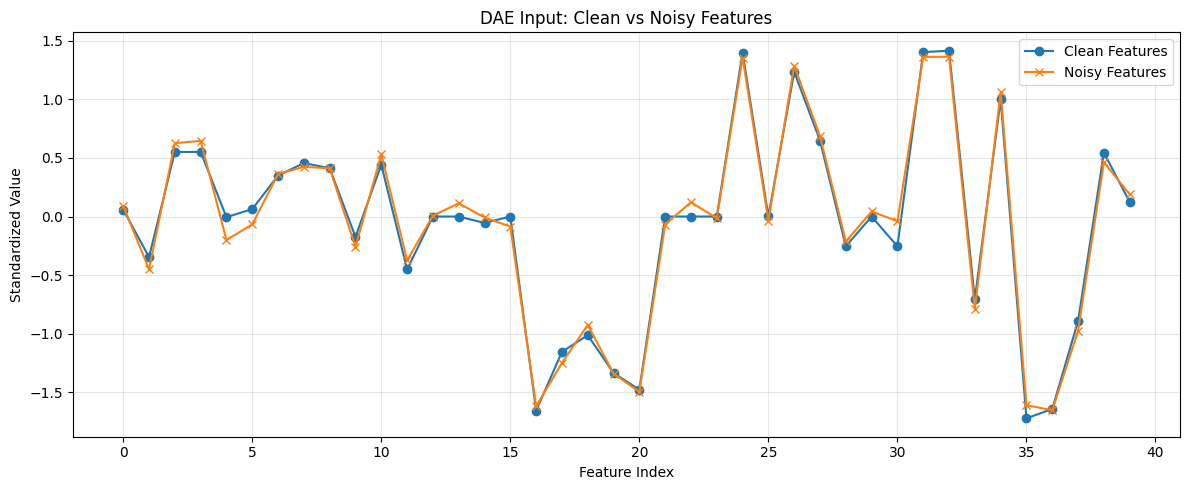

In [ ]:
SAMPLE_INDEX = 0

plt.figure(
    figsize=(12, 5)
)

plt.plot(
    X_train_scaled[SAMPLE_INDEX],
    marker="o",
    label="Clean Features"
)

plt.plot(
    X_train_noisy[SAMPLE_INDEX],
    marker="x",
    label="Noisy Features"
)

plt.xlabel(
    "Feature Index"
)

plt.ylabel(
    "Standardized Value"
)

plt.title(
    "DAE Input: Clean vs Noisy Features"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

noise_plot_path = os.path.join(
    FIGURES_DIR,
    "dae_clean_vs_noisy.png"
)

plt.savefig(
    noise_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Build Denoising Autoencoder

In [ ]:
tf.keras.backend.clear_session()

dae_input = Input(
    shape=(INPUT_DIM,),
    name="DAE_Input"
)

# ---------------------------
# Encoder
# ---------------------------

x = Dense(
    32,
    activation="relu",
    name="DAE_Encoder_32"
)(dae_input)

x = BatchNormalization(
    name="DAE_Encoder_BN"
)(x)

x = Dense(
    16,
    activation="relu",
    name="DAE_Encoder_16"
)(x)

dae_latent = Dense(
    LATENT_DIM,
    activation="linear",
    name="DAE_Latent"
)(x)

# ---------------------------
# Decoder
# ---------------------------

x = Dense(
    16,
    activation="relu",
    name="DAE_Decoder_16"
)(dae_latent)

x = Dense(
    32,
    activation="relu",
    name="DAE_Decoder_32"
)(x)

dae_output = Dense(
    INPUT_DIM,
    activation="linear",
    name="DAE_Output"
)(x)

# Complete DAE
dae = Model(
    inputs=dae_input,
    outputs=dae_output,
    name="Denoising_Autoencoder"
)

dae.summary()

Model: "Denoising_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ DAE_Input (InputLayer)          │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Encoder_32 (Dense)          │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Encoder_BN                  │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Encoder_16 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Latent (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Decoder_16 (Dense)          │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Decoder_32 (Dense)          │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Output (Dense)              │ (None, 40)             │         1,320 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,112 (16.06 KB)

 Trainable params: 4,048 (15.81 KB)

 Non-trainable params: 64 (256.00 B)

Create DAE encoder

In [ ]:
dae_encoder = Model(
    inputs=dae_input,
    outputs=dae_latent,
    name="DAE_Encoder"
)

dae_encoder.summary()

Model: "DAE_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ DAE_Input (InputLayer)          │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Encoder_32 (Dense)          │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Encoder_BN                  │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Encoder_16 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ DAE_Latent (Dense)              │ (None, 8)              │           136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,104 (8.22 KB)

 Trainable params: 2,040 (7.97 KB)

 Non-trainable params: 64 (256.00 B)

Compile DAE

In [ ]:
dae.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mse",

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="reconstruction_mae"
        )
    ]
)

print(
    "DAE compiled successfully."
)

DAE compiled successfully.


DAE callbacks

In [ ]:
best_dae_path = os.path.join(
    DAE_MODEL_DIR,
    "best_dae.keras"
)

dae_early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True,

    verbose=1
)

dae_reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=5,

    min_lr=1e-6,

    verbose=1
)

dae_checkpoint = ModelCheckpoint(

    filepath=best_dae_path,

    monitor="val_loss",

    save_best_only=True,

    verbose=1
)

print("DAE callbacks ready.")

DAE callbacks ready.


Train DAE

In [ ]:
INPUT  = noisy X
TARGET = clean X

In [ ]:
history_dae = dae.fit(

    X_train_noisy,
    X_train_scaled,

    validation_data=(
        X_val_noisy,
        X_val_scaled
    ),

    epochs=100,

    batch_size=256,

    shuffle=True,

    callbacks=[
        dae_early_stopping,
        dae_reduce_lr,
        dae_checkpoint
    ],

    verbose=1
)

Epoch 1/100
300/310 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6120 - reconstruction_mae: 0.5229
Epoch 1: val_loss improved from None to 1.16684, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/denoising_autoencoder/best_dae.keras

Epoch 1: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/denoising_autoencoder/best_dae.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4551 - reconstruction_mae: 0.4244 - val_loss: 1.1668 - val_reconstruction_mae: 0.6353 - learning_rate: 0.0010
Epoch 2/100
305/310 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2595 - reconstruction_mae: 0.2952
Epoch 2: val_loss improved from 1.16684 to 1.05251, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/denoising_autoencoder/best_dae.keras

Epoch 2: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/denoising_autoencoder/best_dae.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2447 - reconstruction_m

Plot DAE training history

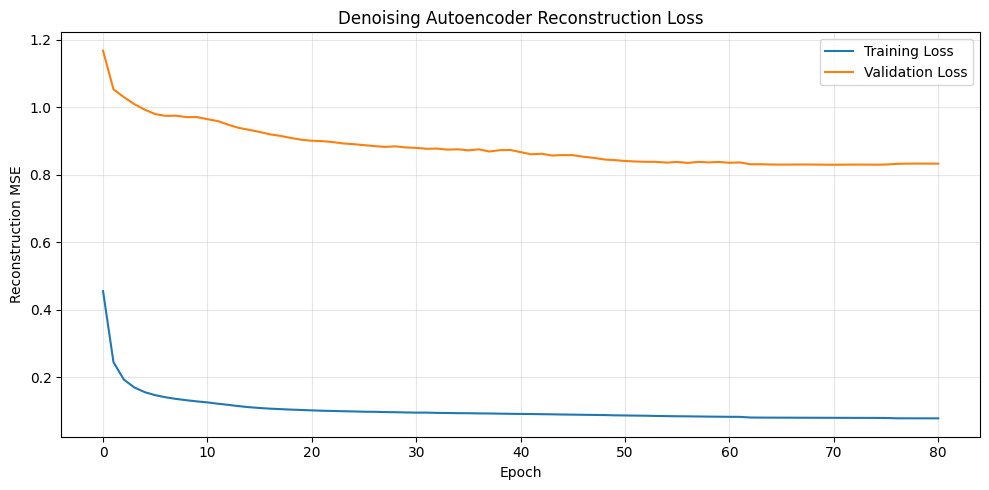

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/figures/dae_reconstruction_loss.png


In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_dae.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_dae.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Reconstruction MSE"
)

plt.title(
    "Denoising Autoencoder Reconstruction Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

dae_loss_path = os.path.join(
    FIGURES_DIR,
    "dae_reconstruction_loss.png"
)

plt.savefig(
    dae_loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    dae_loss_path
)

Evaluate DAE reconstruction

In [ ]:
test_rng = np.random.default_rng(
    SEED + 1
)

test_noise = test_rng.normal(
    loc=0.0,
    scale=NOISE_FACTOR,
    size=X_test_scaled.shape
).astype(np.float32)

X_test_noisy = (
    X_test_scaled +
    test_noise
).astype(np.float32)

In [ ]:
train_dae_reconstruction = (
    dae.predict(
        X_train_noisy,
        batch_size=256,
        verbose=0
    )
)

val_dae_reconstruction = (
    dae.predict(
        X_val_noisy,
        batch_size=256,
        verbose=0
    )
)

test_dae_reconstruction = (
    dae.predict(
        X_test_noisy,
        batch_size=256,
        verbose=0
    )
)

Calculate DAE reconstruction metrics

In [ ]:
def reconstruction_metrics(
    clean,
    reconstructed
):

    mse = np.mean(
        (
            clean -
            reconstructed
        ) ** 2
    )

    mae = np.mean(
        np.abs(
            clean -
            reconstructed
        )
    )

    return mse, mae

In [ ]:
train_dae_mse, train_dae_mae = (
    reconstruction_metrics(
        X_train_scaled,
        train_dae_reconstruction
    )
)

val_dae_mse, val_dae_mae = (
    reconstruction_metrics(
        X_val_scaled,
        val_dae_reconstruction
    )
)

test_dae_mse, test_dae_mae = (
    reconstruction_metrics(
        X_test_scaled,
        test_dae_reconstruction
    )
)

print("=" * 60)
print("DAE RECONSTRUCTION RESULTS")
print("=" * 60)

print(
    f"Train MSE      : {train_dae_mse:.6f}"
)

print(
    f"Validation MSE : {val_dae_mse:.6f}"
)

print(
    f"Test MSE       : {test_dae_mse:.6f}"
)

print()

print(
    f"Train MAE      : {train_dae_mae:.6f}"
)

print(
    f"Validation MAE : {val_dae_mae:.6f}"
)

print(
    f"Test MAE       : {test_dae_mae:.6f}"
)

DAE RECONSTRUCTION RESULTS
Train MSE      : 0.076345
Validation MSE : 0.829169
Test MSE       : 0.832220

Train MAE      : 0.145318
Validation MAE : 0.378841
Test MAE       : 0.377377


Save DAE reconstruction results

In [ ]:
dae_reconstruction_results = pd.DataFrame({

    "Dataset": [
        "Train",
        "Validation",
        "Test"
    ],

    "Reconstruction_MSE": [
        train_dae_mse,
        val_dae_mse,
        test_dae_mse
    ],

    "Reconstruction_MAE": [
        train_dae_mae,
        val_dae_mae,
        test_dae_mae
    ]
})

display(
    dae_reconstruction_results.round(6)
)

dae_reconstruction_path = os.path.join(
    METRICS_DIR,
    "dae_reconstruction_metrics.csv"
)

dae_reconstruction_results.to_csv(
    dae_reconstruction_path,
    index=False
)

print(
    "Saved:",
    dae_reconstruction_path
)

,Dataset,Reconstruction_MSE,Reconstruction_MAE
0,Train,0.076345,0.145318
1,Validation,0.829169,0.378841
2,Test,0.832220,0.377377


Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/dae_reconstruction_metrics.csv


Extract DAE latent features

In [ ]:
Z_train_dae = dae_encoder.predict(
    X_train_scaled,
    batch_size=256,
    verbose=0
)

Z_val_dae = dae_encoder.predict(
    X_val_scaled,
    batch_size=256,
    verbose=0
)

Z_test_dae = dae_encoder.predict(
    X_test_scaled,
    batch_size=256,
    verbose=0
)

print("=" * 60)
print("DAE LATENT REPRESENTATION")
print("=" * 60)

print(
    "Original train:",
    X_train_scaled.shape
)

print(
    "DAE train:",
    Z_train_dae.shape
)

print()

print(
    "Original validation:",
    X_val_scaled.shape
)

print(
    "DAE validation:",
    Z_val_dae.shape
)

print()

print(
    "Original test:",
    X_test_scaled.shape
)

print(
    "DAE test:",
    Z_test_dae.shape
)

DAE LATENT REPRESENTATION
Original train: (79200, 40)
DAE train: (79200, 8)

Original validation: (300, 40)
DAE validation: (300, 8)

Original test: (300, 40)
DAE test: (300, 8)


Verify latent values

In [ ]:
print(
    "Train finite:",
    np.isfinite(
        Z_train_dae
    ).all()
)

print(
    "Validation finite:",
    np.isfinite(
        Z_val_dae
    ).all()
)

print(
    "Test finite:",
    np.isfinite(
        Z_test_dae
    ).all()
)

print(
    "\nDAE latent mean:",
    np.mean(
        Z_train_dae
    )
)

print(
    "DAE latent std:",
    np.std(
        Z_train_dae
    )
)

Train finite: True
Validation finite: True
Test finite: True

DAE latent mean: -0.6348919
DAE latent std: 2.388295


Create latent feature names

In [ ]:
DAE_LATENT_FEATURES = [
    f"DAE_Latent_{i}"
    for i in range(
        1,
        LATENT_DIM + 1
    )
]

print(
    DAE_LATENT_FEATURES
)

['DAE_Latent_1', 'DAE_Latent_2', 'DAE_Latent_3', 'DAE_Latent_4', 'DAE_Latent_5', 'DAE_Latent_6', 'DAE_Latent_7', 'DAE_Latent_8']


Create DAE latent DataFrames

In [ ]:
train_dae_latent_df = pd.DataFrame(
    Z_train_dae,
    columns=DAE_LATENT_FEATURES
)

val_dae_latent_df = pd.DataFrame(
    Z_val_dae,
    columns=DAE_LATENT_FEATURES
)

test_dae_latent_df = pd.DataFrame(
    Z_test_dae,
    columns=DAE_LATENT_FEATURES
)

In [ ]:
train_dae_latent_df = pd.DataFrame(
    Z_train_dae,
    columns=DAE_LATENT_FEATURES
)

val_dae_latent_df = pd.DataFrame(
    Z_val_dae,
    columns=DAE_LATENT_FEATURES
)

test_dae_latent_df = pd.DataFrame(
    Z_test_dae,
    columns=DAE_LATENT_FEATURES
)

In [ ]:
ID_COLUMNS = [
    col
    for col in [
        "id",
        "series_key",
        "date"
    ]
    if col in train_df.columns
]

print(
    "ID columns:",
    ID_COLUMNS
)

for col in ID_COLUMNS:

    train_dae_latent_df[col] = (
        train_df[col]
        .reset_index(drop=True)
    )

    val_dae_latent_df[col] = (
        val_df[col]
        .reset_index(drop=True)
    )

    test_dae_latent_df[col] = (
        test_df[col]
        .reset_index(drop=True)
    )

ID columns: ['id', 'series_key', 'date']


In [ ]:
for target in TARGETS:

    train_dae_latent_df[target] = (
        train_df[target]
        .reset_index(drop=True)
    )

    val_dae_latent_df[target] = (
        val_df[target]
        .reset_index(drop=True)
    )

    test_dae_latent_df[target] = (
        test_df[target]
        .reset_index(drop=True)
    )

In [ ]:
print(
    "DAE train latent:",
    train_dae_latent_df.shape
)

print(
    "DAE validation latent:",
    val_dae_latent_df.shape
)

print(
    "DAE test latent:",
    test_dae_latent_df.shape
)

display(
    train_dae_latent_df.head()
)

DAE train latent: (79200, 39)
DAE validation latent: (300, 39)
DAE test latent: (300, 39)


,DAE_Latent_1,DAE_Latent_2,DAE_Latent_3,DAE_Latent_4,DAE_Latent_5,DAE_Latent_6,DAE_Latent_7,DAE_Latent_8,id,series_key,...,target_day_19,target_day_20,target_day_21,target_day_22,target_day_23,target_day_24,target_day_25,target_day_26,target_day_27,target_day_28
0,0.490033,4.554899,-2.653831,-1.296741,-0.854156,-3.239646,-0.603427,-3.267988,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,1.0,2.0,1.0,2.0,1.0,0.0,0.0,3.0,2.0,1.0
1,0.488290,4.466017,-2.781500,-1.231164,-0.849234,-3.102875,-0.806788,-2.894477,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,3.0,2.0,1.0,0.0,2.0,2.0,0.0,1.0,0.0,0.0
2,-1.392912,5.506238,-4.032904,-0.978660,-0.369920,-3.460398,-0.938734,-2.076523,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0
3,-0.420276,4.180258,-3.169649,0.072213,-0.816518,-3.962103,-0.886089,-0.424355,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,0.0,2.0,0.0,3.0,1.0,3.0,0.0,2.0,0.0,2.0
4,-0.236223,3.724388,-3.144452,0.174655,-0.987669,-3.582084,-0.614680,-0.162219,FOODS_1_005_TX_3_evaluation,FOODS_1_005_TX_3,...,2.0,0.0,2.0,3.0,4.0,5.0,5.0,6.0,7.0,2.0


Save DAE latent datasets

In [ ]:
DAE_TRAIN_PATH = os.path.join(
    LATENT_DIR,
    "dae_train_latent.parquet"
)

DAE_VAL_PATH = os.path.join(
    LATENT_DIR,
    "dae_validation_latent.parquet"
)

DAE_TEST_PATH = os.path.join(
    LATENT_DIR,
    "dae_test_latent.parquet"
)

train_dae_latent_df.to_parquet(
    DAE_TRAIN_PATH,
    index=False
)

val_dae_latent_df.to_parquet(
    DAE_VAL_PATH,
    index=False
)

test_dae_latent_df.to_parquet(
    DAE_TEST_PATH,
    index=False
)

print(
    "DAE latent datasets saved successfully."
)

DAE latent datasets saved successfully.


Save DAE and encoder

In [ ]:
dae_model_path = os.path.join(
    DAE_MODEL_DIR,
    "dae_final.keras"
)

dae_encoder_path = os.path.join(
    DAE_MODEL_DIR,
    "dae_encoder.keras"
)

dae.save(
    dae_model_path
)

dae_encoder.save(
    dae_encoder_path
)

print(
    "DAE saved:",
    dae_model_path
)

print(
    "DAE encoder saved:",
    dae_encoder_path
)

DAE saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/denoising_autoencoder/dae_final.keras
DAE encoder saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/denoising_autoencoder/dae_encoder.keras


Save DAE configuration

In [ ]:
dae_config = {

    "model":
        "Denoising Autoencoder",

    "input_dimension":
        INPUT_DIM,

    "latent_dimension":
        LATENT_DIM,

    "noise_type":
        "Gaussian",

    "noise_factor":
        NOISE_FACTOR,

    "encoder_architecture": [
        INPUT_DIM,
        32,
        16,
        LATENT_DIM
    ],

    "decoder_architecture": [
        LATENT_DIM,
        16,
        32,
        INPUT_DIM
    ],

    "reconstruction_loss":
        "MSE",

    "optimizer":
        "Adam",

    "learning_rate":
        0.001,

    "latent_features":
        DAE_LATENT_FEATURES
}

DAE_CONFIG_PATH = os.path.join(
    DAE_MODEL_DIR,
    "dae_config.json"
)

with open(
    DAE_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        dae_config,
        f,
        indent=4
    )

print(
    "DAE configuration saved."
)

DAE configuration saved.


Visualize DAE latent space with PCA

In [ ]:
from sklearn.decomposition import PCA

dae_pca = PCA(
    n_components=2,
    random_state=SEED
)

Z_train_dae_pca = (
    dae_pca.fit_transform(
        Z_train_dae
    )
)

print(
    "Explained variance:",
    dae_pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    dae_pca.explained_variance_ratio_.sum()
)

Explained variance: [0.29060578 0.23273736]
Total explained variance: 0.52334315


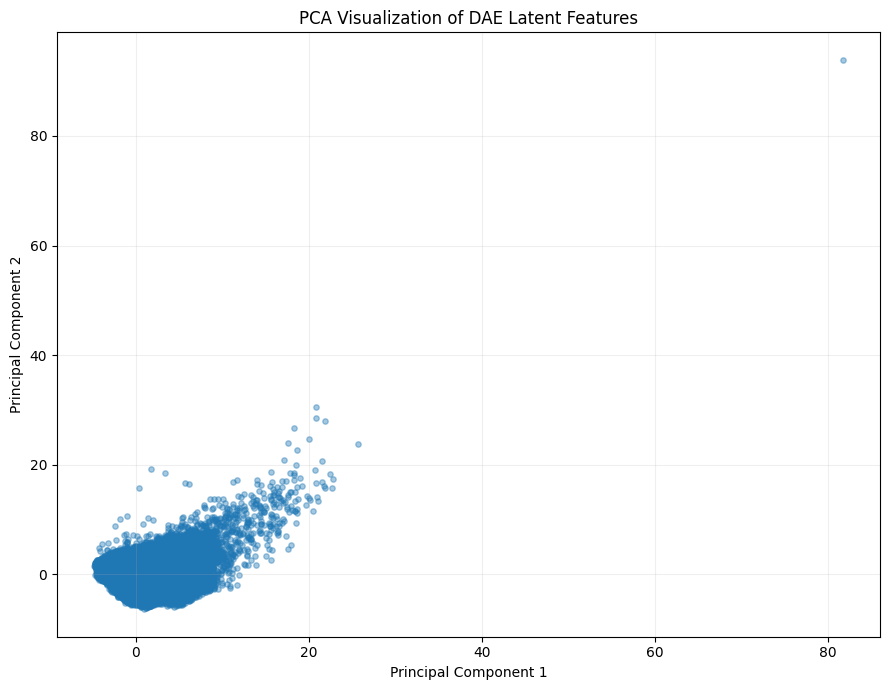

In [ ]:
plt.figure(
    figsize=(9, 7)
)

plt.scatter(
    Z_train_dae_pca[:, 0],
    Z_train_dae_pca[:, 1],
    alpha=0.4,
    s=15
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.title(
    "PCA Visualization of DAE Latent Features"
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

dae_pca_path = os.path.join(
    FIGURES_DIR,
    "dae_latent_pca.png"
)

plt.savefig(
    dae_pca_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Build DAE + MLP forecaster

In [ ]:
tf.keras.backend.clear_session()

dae_mlp_model = tf.keras.Sequential([

    Input(
        shape=(LATENT_DIM,)
    ),

    Dense(
        64,
        activation="relu"
    ),

    BatchNormalization(),

    Dropout(
        0.20
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(
        0.10
    ),

    Dense(
        HORIZON,
        activation="linear"
    )
])

dae_mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 28)             │           924 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,836 (14.98 KB)

 Trainable params: 3,708 (14.48 KB)

 Non-trainable params: 128 (512.00 B)

Compile DAE + MLP

In [ ]:
dae_mlp_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mae",

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        )
    ]
)

In [ ]:
dae_mlp_early_stop = EarlyStopping(

    monitor="val_loss",

    patience=8,

    restore_best_weights=True,

    verbose=1
)

dae_mlp_reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=4,

    min_lr=1e-6,

    verbose=1
)

print(
    "DAE + MLP ready."
)

DAE + MLP ready.


Train DAE + MLP

In [ ]:
history_dae_mlp = (
    dae_mlp_model.fit(

        Z_train_dae,
        y_train,

        validation_data=(
            Z_val_dae,
            y_val
        ),

        epochs=60,

        batch_size=256,

        callbacks=[
            dae_mlp_early_stop,
            dae_mlp_reduce_lr
        ],

        verbose=1
    )
)

Generate DAE + MLP forecasts

In [ ]:
val_pred_dae_mlp = (
    dae_mlp_model.predict(
        Z_val_dae,
        batch_size=256,
        verbose=0
    )
)

test_pred_dae_mlp = (
    dae_mlp_model.predict(
        Z_test_dae,
        batch_size=256,
        verbose=0
    )
)

val_pred_dae_mlp = np.clip(
    val_pred_dae_mlp,
    0,
    None
)

test_pred_dae_mlp = np.clip(
    test_pred_dae_mlp,
    0,
    None
)

print(
    "Validation:",
    val_pred_dae_mlp.shape
)

print(
    "Test:",
    test_pred_dae_mlp.shape
)

Validation: (300, 28)
Test: (300, 28)


Forecast evaluation function

In [ ]:
def forecast_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    y_pred = np.clip(
        y_pred,
        0,
        None
    )

    # MAE
    mae = np.mean(
        np.abs(
            y_true -
            y_pred
        )
    )

    # RMSE
    rmse = np.sqrt(
        np.mean(
            (
                y_true -
                y_pred
            ) ** 2
        )
    )

    # WAPE
    wape_denominator = np.sum(
        np.abs(y_true)
    )

    if wape_denominator > 0:

        wape = (
            np.sum(
                np.abs(
                    y_true -
                    y_pred
                )
            )
            /
            wape_denominator
        ) * 100

    else:
        wape = np.nan

    # sMAPE
    smape_denominator = (
        np.abs(y_true)
        +
        np.abs(y_pred)
    )

    smape_numerator = (
        2 *
        np.abs(
            y_true -
            y_pred
        )
    )

    smape_values = np.divide(

        smape_numerator,

        smape_denominator,

        out=np.zeros_like(
            smape_numerator,
            dtype=np.float64
        ),

        where=(
            smape_denominator != 0
        )
    )

    smape = (
        np.mean(
            smape_values
        ) * 100
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "WAPE": float(wape),
        "sMAPE": float(smape)
    }

Evaluate DAE + MLP

In [ ]:
dae_mlp_val_metrics = (
    forecast_metrics(
        y_val,
        val_pred_dae_mlp
    )
)

dae_mlp_test_metrics = (
    forecast_metrics(
        y_test,
        test_pred_dae_mlp
    )
)

print("=" * 60)
print("DAE + MLP RESULTS")
print("=" * 60)

print("\nVALIDATION")

for metric, value in (
    dae_mlp_val_metrics.items()
):

    print(
        f"{metric:8s}: {value:.4f}"
    )

print("\nTEST")

for metric, value in (
    dae_mlp_test_metrics.items()
):

    print(
        f"{metric:8s}: {value:.4f}"
    )

DAE + MLP RESULTS

VALIDATION
MAE     : 1.2199
RMSE    : 2.9660
WAPE    : 103.5550
sMAPE   : 117.8677

TEST
MAE     : 1.1905
RMSE    : 2.8978
WAPE    : 100.3419
sMAPE   : 128.1398


Save DAE + MLP model

In [ ]:
DAE_MLP_MODEL_PATH = os.path.join(
    DAE_MODEL_DIR,
    "dae_mlp_forecaster.keras"
)

dae_mlp_model.save(
    DAE_MLP_MODEL_PATH
)

print(
    "DAE + MLP model saved:"
)

print(
    DAE_MLP_MODEL_PATH
)

DAE + MLP model saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/models/denoising_autoencoder/dae_mlp_forecaster.keras


Save DAE + MLP predictions

In [ ]:
if "series_key" in test_df.columns:

    test_ids = (
        test_df[
            "series_key"
        ]
        .astype(str)
        .values
    )

else:

    test_ids = (
        test_df[
            "id"
        ]
        .astype(str)
        .values
    )


prediction_records = []

for i in range(
    len(test_df)
):

    for h in range(
        HORIZON
    ):

        prediction_records.append({

            "series_id":
                test_ids[i],

            "forecast_day":
                h + 1,

            "actual":
                float(
                    y_test[i, h]
                ),

            "prediction":
                float(
                    test_pred_dae_mlp[
                        i,
                        h
                    ]
                ),

            "model":
                "DAE + MLP"
        })


dae_mlp_predictions = pd.DataFrame(
    prediction_records
)

display(
    dae_mlp_predictions.head()
)

,series_id,forecast_day,actual,prediction,model
0,FOODS_1_005_TX_3,1,1.0,0.000000,DAE + MLP
1,FOODS_1_005_TX_3,2,0.0,0.193559,DAE + MLP
2,FOODS_1_005_TX_3,3,4.0,0.160662,DAE + MLP
3,FOODS_1_005_TX_3,4,1.0,0.972738,DAE + MLP
4,FOODS_1_005_TX_3,5,1.0,0.000000,DAE + MLP


In [ ]:
DAE_PREDICTION_PATH = os.path.join(
    PREDICTIONS_DIR,
    "dae_mlp_test_predictions.csv"
)

dae_mlp_predictions.to_csv(
    DAE_PREDICTION_PATH,
    index=False
)

print(
    "Predictions saved:",
    DAE_PREDICTION_PATH
)

Predictions saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/predictions/dae_mlp_test_predictions.csv


Compare MLP, AE+MLP and DAE+MLP

In [ ]:
baseline_path = os.path.join(
    METRICS_DIR,
    "baseline_test_metrics.csv"
)

baseline_results = pd.read_csv(
    baseline_path
)

display(
    baseline_results
)

,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.255476,2.874394,105.819787,86.528972
1,MLP,0.900348,1.843470,75.887268,151.595465
2,LightGBM,0.846885,1.805397,71.381020,102.498205


In [ ]:
ae_comparison_path = os.path.join(
    METRICS_DIR,
    "ae_mlp_comparison.csv"
)

if os.path.exists(
    ae_comparison_path
):

    ae_results = pd.read_csv(
        ae_comparison_path
    )

    print(
        "Step 7 AE results loaded."
    )

else:

    ae_results = baseline_results.copy()

    print(
        "AE comparison file not found. "
        "Using baseline results only."
    )

Step 7 AE results loaded.


In [ ]:
dae_result = pd.DataFrame([{

    "Model":
        "DAE + MLP",

    "MAE":
        dae_mlp_test_metrics[
            "MAE"
        ],

    "RMSE":
        dae_mlp_test_metrics[
            "RMSE"
        ],

    "WAPE":
        dae_mlp_test_metrics[
            "WAPE"
        ],

    "sMAPE":
        dae_mlp_test_metrics[
            "sMAPE"
        ]
}])

In [ ]:
comparison_results = (
    ae_results[
        ae_results["Model"]
        != "DAE + MLP"
    ]
    .copy()
)

comparison_results = pd.concat(
    [
        comparison_results,
        dae_result
    ],
    ignore_index=True
)

display(
    comparison_results.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644
4,DAE + MLP,1.1905,2.8978,100.3419,128.1398


Save updated comparison

In [ ]:
DAE_COMPARISON_PATH = os.path.join(
    METRICS_DIR,
    "dae_model_comparison.csv"
)

comparison_results.to_csv(
    DAE_COMPARISON_PATH,
    index=False
)

print(
    "Comparison saved:"
)

print(
    DAE_COMPARISON_PATH
)

Comparison saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/dae_model_comparison.csv


Compare AE and DAE reconstruction

In [ ]:
ae_reconstruction_path = os.path.join(
    METRICS_DIR,
    "ae_reconstruction_metrics.csv"
)

if os.path.exists(
    ae_reconstruction_path
):

    ae_rec = pd.read_csv(
        ae_reconstruction_path
    )

    ae_rec["Model"] = "AE"

    dae_rec = (
        dae_reconstruction_results
        .copy()
    )

    dae_rec["Model"] = "DAE"

    reconstruction_comparison = (
        pd.concat(
            [
                ae_rec,
                dae_rec
            ],
            ignore_index=True
        )
    )

    display(
        reconstruction_comparison.round(6)
    )

else:

    print(
        "Step 7 AE reconstruction file "
        "not found."
    )

,Dataset,Reconstruction_MSE,Reconstruction_MAE,Model
0,Train,0.170813,0.233573,AE
1,Validation,1.276855,0.709960,AE
2,Test,1.231944,0.692925,AE
3,Train,0.076345,0.145318,DAE
4,Validation,0.829169,0.378841,DAE
5,Test,0.832220,0.377377,DAE


Plot DAE+MLP training

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_dae_mlp.history[
        "loss"
    ],
    label="Training MAE"
)

plt.plot(
    history_dae_mlp.history[
        "val_loss"
    ],
    label="Validation MAE"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "DAE + MLP Forecasting Training History"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

dae_mlp_history_path = os.path.join(
    FIGURES_DIR,
    "dae_mlp_training_history.png"
)

plt.savefig(
    dae_mlp_history_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'history_dae_mlp' is not defined

<Figure size 1000x500 with 0 Axes>

28-day horizon analysis

In [ ]:
dae_horizon_mae = np.mean(
    np.abs(
        y_test -
        test_pred_dae_mlp
    ),
    axis=0
)

dae_horizon_df = pd.DataFrame({

    "Forecast_Day":
        np.arange(
            1,
            HORIZON + 1
        ),

    "DAE_MLP_MAE":
        dae_horizon_mae
})

display(
    dae_horizon_df
)

,Forecast_Day,DAE_MLP_MAE
0,1,1.026513
1,2,1.044316
2,3,1.020405
3,4,1.082893
4,5,1.052699
5,6,1.311522
6,7,1.410097
7,8,1.043333
8,9,1.192513
9,10,0.811461


In [ ]:
DAE_HORIZON_PATH = os.path.join(
    METRICS_DIR,
    "dae_mlp_horizon_mae.csv"
)

dae_horizon_df.to_csv(
    DAE_HORIZON_PATH,
    index=False
)

In [ ]:
display(comparison_results[['Model', 'MAE']].round(4))

,Model,MAE
0,Seasonal Naive,1.2555
1,MLP,0.9003
2,LightGBM,0.8469
3,AE + MLP,1.0662
4,DAE + MLP,1.1905


Compare AE+MLP vs DAE+MLP by forecast day

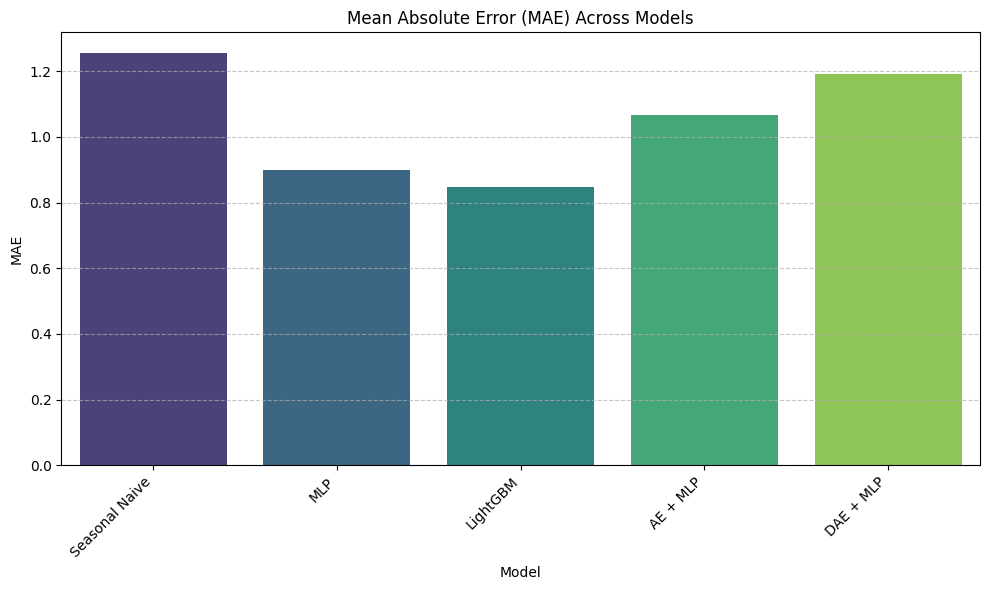

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='MAE', data=comparison_results, palette='viridis')
plt.title('Mean Absolute Error (MAE) Across Models')
plt.xlabel('Model')
plt.ylabel('MAE')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

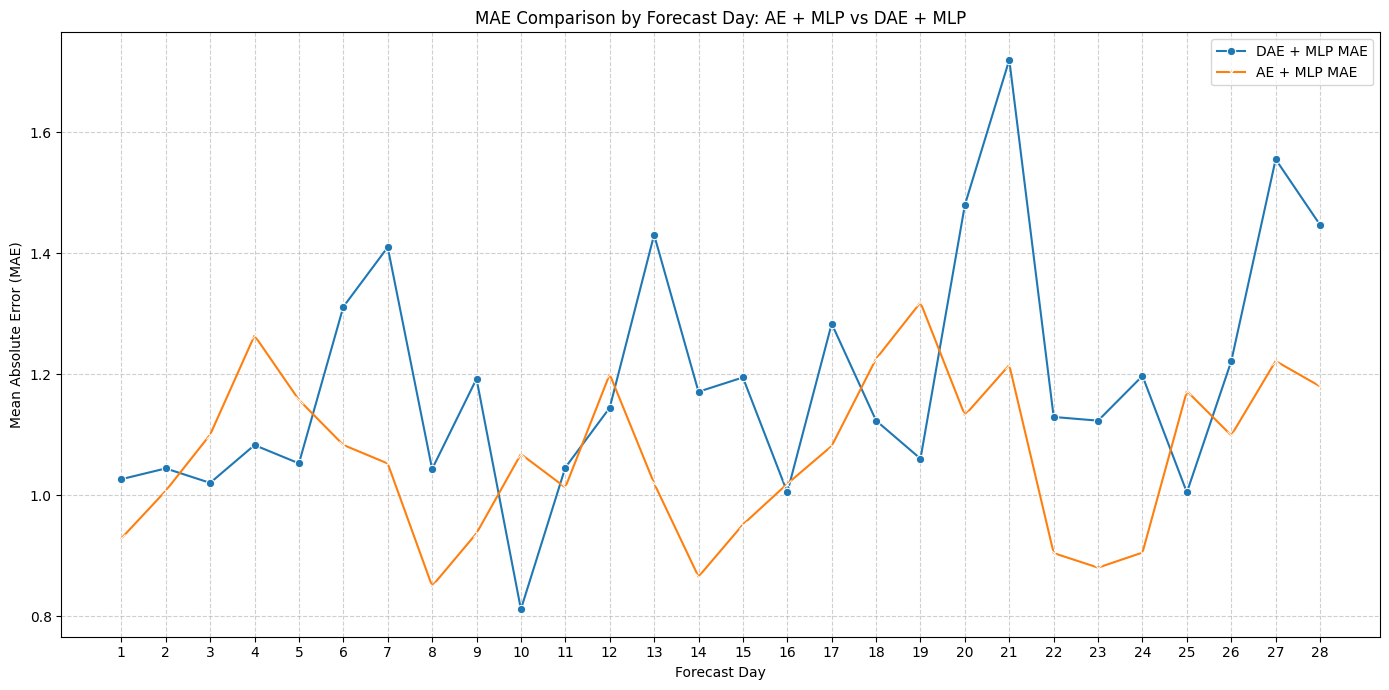

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/figures/dae_ae_mlp_horizon_mae_comparison.png


In [ ]:
AE_PREDICTION_PATH = os.path.join(
    PREDICTIONS_DIR,
    "ae_mlp_test_predictions.csv"
)

if os.path.exists(AE_PREDICTION_PATH):
    ae_mlp_predictions = pd.read_csv(AE_PREDICTION_PATH)

    # Calculate horizon MAE for AE + MLP
    ae_horizon_df_raw = ae_mlp_predictions.groupby('forecast_day').apply(
        lambda x: np.mean(np.abs(x['actual'] - x['prediction']))
    ).reset_index(name='AE_MLP_MAE')

    ae_horizon_df = ae_horizon_df_raw.rename(columns={'forecast_day': 'Forecast_Day'})

    # Merge DAE and AE horizon dataframes
    comparison_horizon_df = pd.merge(
        dae_horizon_df,
        ae_horizon_df,
        on='Forecast_Day',
        how='outer'
    )

    # Plotting
    plt.figure(figsize=(14, 7))
    sns.lineplot(x='Forecast_Day', y='DAE_MLP_MAE', data=comparison_horizon_df, label='DAE + MLP MAE', marker='o')
    sns.lineplot(x='Forecast_Day', y='AE_MLP_MAE', data=comparison_horizon_df, label='AE + MLP MAE', marker='x')

    plt.title('MAE Comparison by Forecast Day: AE + MLP vs DAE + MLP')
    plt.xlabel('Forecast Day')
    plt.ylabel('Mean Absolute Error (MAE)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.xticks(
        np.arange(1, HORIZON + 1, 1)
    )
    plt.tight_layout()

    dae_ae_horizon_path = os.path.join(
        FIGURES_DIR,
        "dae_ae_mlp_horizon_mae_comparison.png"
    )

    plt.savefig(
        dae_ae_horizon_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    print("Saved:", dae_ae_horizon_path)

else:
    print(f"AE MLP prediction file not found at: {AE_PREDICTION_PATH}")
    print("Cannot perform comparison by forecast day without AE + MLP predictions.")

Final Step 8 verification

In [ ]:
print("=" * 75)
print("STEP 8 - DENOISING AUTOENCODER VERIFICATION")
print("=" * 75)

print("\n1. DATA")
print("-" * 40)

print(
    "Original input dimension:",
    INPUT_DIM
)

print(
    "Forecast horizon:",
    HORIZON
)

print(
    "Noise factor:",
    NOISE_FACTOR
)


print("\n2. DAE REPRESENTATION")
print("-" * 40)

print(
    "Train:",
    X_train_scaled.shape,
    "->",
    Z_train_dae.shape
)

print(
    "Validation:",
    X_val_scaled.shape,
    "->",
    Z_val_dae.shape
)

print(
    "Test:",
    X_test_scaled.shape,
    "->",
    Z_test_dae.shape
)


print("\n3. DAE RECONSTRUCTION")
print("-" * 40)

print(
    f"Train MSE      : "
    f"{train_dae_mse:.6f}"
)

print(
    f"Validation MSE : "
    f"{val_dae_mse:.6f}"
)

print(
    f"Test MSE       : "
    f"{test_dae_mse:.6f}"
)


print("\n4. DAE + MLP TEST RESULTS")
print("-" * 40)

for metric, value in (
    dae_mlp_test_metrics.items()
):

    print(
        f"{metric:8s}: "
        f"{value:.4f}"
    )


print("\n5. SAVED FILES")
print("-" * 40)

files_to_check = {

    "DAE Model":
        dae_model_path,

    "DAE Encoder":
        dae_encoder_path,

    "DAE + MLP":
        DAE_MLP_MODEL_PATH,

    "DAE Train Latent":
        DAE_TRAIN_PATH,

    "DAE Validation Latent":
        DAE_VAL_PATH,

    "DAE Test Latent":
        DAE_TEST_PATH,

    "DAE Config":
        DAE_CONFIG_PATH,

    "DAE Predictions":
        DAE_PREDICTION_PATH,

    "DAE Comparison":
        DAE_COMPARISON_PATH
}

all_saved = True

for name, path in (
    files_to_check.items()
):

    exists = os.path.exists(
        path
    )

    print(
        f"{name:25s}:",
        "FOUND"
        if exists
        else "MISSING"
    )

    if not exists:
        all_saved = False


print("\n" + "=" * 75)

if all_saved:

    print(
        "STEP 8 COMPLETED SUCCESSFULLY"
    )

    print(
        "41 FEATURES -> NOISE -> DAE -> "
        "8 LATENT FEATURES -> MLP -> "
        "28-DAY FORECAST"
    )

else:

    print(
        "STEP 8 INCOMPLETE - "
        "CHECK MISSING FILES"
    )

print("=" * 75)

STEP 8 - DENOISING AUTOENCODER VERIFICATION

1. DATA
----------------------------------------
Original input dimension: 40
Forecast horizon: 28
Noise factor: 0.1

2. DAE REPRESENTATION
----------------------------------------
Train: (79200, 40) -> (79200, 8)
Validation: (300, 40) -> (300, 8)
Test: (300, 40) -> (300, 8)

3. DAE RECONSTRUCTION
----------------------------------------
Train MSE      : 0.076345
Validation MSE : 0.829169
Test MSE       : 0.832220

4. DAE + MLP TEST RESULTS
----------------------------------------
MAE     : 1.1905
RMSE    : 2.8978
WAPE    : 100.3419
sMAPE   : 128.1398

5. SAVED FILES
----------------------------------------
DAE Model                : FOUND
DAE Encoder              : FOUND
DAE + MLP                : FOUND
DAE Train Latent         : FOUND
DAE Validation Latent    : FOUND
DAE Test Latent          : FOUND
DAE Config               : FOUND
DAE Predictions          : FOUND
DAE Comparison           : FOUND

STEP 8 COMPLETED SUCCESSFULLY
41 FEATURES 